# Day 188 — Process Mining with pm4py (Part 2)
### Month 11: Data Engineering Portfolio | LogiTrack India — Conformance Checking, Fitness/Precision, KPI Dashboard

**Continues from Day 187** (event log construction, variant analysis, process discovery via Inductive Miner).
**Dataset:** `logitrack_process_log_RAW.csv` — same generation methodology, seed=187, 150 shipment cases, 9 activities.
**New scope today:** Conformance checking (token-based replay vs. alignments), the four process-mining quality
dimensions (fitness, precision, generalization, simplicity), and a carrier-level KPI dashboard.

**Note on today's log:** the rework loop generation was extended slightly from Day 187 to include multi-attempt
redeliveries, so this session's printed case/event counts are the authoritative numbers for Day 188 — per the NRA
rule, printed output always wins over a remembered number from a prior session.

---


## Setup — run this first

In [19]:
!pip install pm4py --quiet


In [28]:
import pandas as pd
import numpy as np
import pm4py
import matplotlib.pyplot as plt
import warnings
import matplotlib
matplotlib.rcParams['font.family'] = 'sans-serif'
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Arial'
pd.set_option('display.max_columns', None)
print("pm4py version:", pm4py.__version__)


pm4py version: 2.7.23.1


## SECTION 1: Raw Data — DO NOT MODIFY

Same shipment-lifecycle log structure as Day 187. **Do not edit this cell.** Every transformation, filter, or
model built today lives in a separate variable/object downstream — the raw event log stays untouched, exactly
like a client's source CSV.

**Columns:** `case_id` (trace/process instance) · `activity` (event) · `timestamp` · `resource` · `carrier` · `region`


In [21]:
# ============================================================
# LOCKED RAW DATA — DO NOT MODIFY THIS CELL
# LogiTrack India Shipment Process Log | seed=187 | 150 cases
# ============================================================
np.random.seed(187)

N_CASES = 150
CARRIERS = ["BlueDart", "Delhivery", "Ecom Express", "XpressBees", "DTDC"]
AGENTS = [f"Agent_{i:02d}" for i in range(1, 13)]
REGIONS = ["North", "South", "East", "West", "Central"]

CARRIER_SUCCESS_RATE = {
    "BlueDart": 0.90, "Delhivery": 0.85, "Ecom Express": 0.80,
    "XpressBees": 0.62, "DTDC": 0.78
}

from datetime import datetime, timedelta
rows = []
start_base = datetime(2026, 4, 1, 8, 0, 0)

def generate_case(case_num):
    case_id = f"SHIP{case_num:04d}"
    carrier = np.random.choice(CARRIERS)
    region = np.random.choice(REGIONS)
    agent = np.random.choice(AGENTS)
    success_rate = CARRIER_SUCCESS_RATE[carrier]
    t = start_base + timedelta(days=int(np.random.uniform(0, 30)), hours=int(np.random.uniform(0, 10)))
    state = {"t": t}

    def add(activity, hours_gap, resource=None):
        state["t"] = state["t"] + timedelta(hours=float(hours_gap))
        rows.append({"case_id": case_id, "activity": activity, "timestamp": state["t"],
                     "resource": resource if resource else agent, "carrier": carrier, "region": region})

    add("Order Placed", np.random.uniform(0, 1), resource="System")
    add("Packed", np.random.uniform(2, 8), resource=f"Warehouse_{region}")
    add("Shipped", np.random.uniform(1, 4))
    add("In Transit", np.random.uniform(6, 30))
    add("Out for Delivery", np.random.uniform(4, 20))

    delivered = np.random.random() < success_rate
    if delivered:
        add("Delivered", np.random.uniform(1, 6))
    else:
        # Rework loop: courier can fail and retry 1-2 times before a successful delivery
        n_attempts = np.random.choice([1, 2], p=[0.7, 0.3])
        for attempt in range(n_attempts):
            add("Failed Delivery Attempt", np.random.uniform(1, 6))
            add("Returned to Hub", np.random.uniform(2, 10))
            add("Redelivery Attempt", np.random.uniform(6, 24))
        add("Delivered", np.random.uniform(1, 6))

for case_num in range(1, N_CASES + 1):
    generate_case(case_num)

df_raw = pd.DataFrame(rows)
print("Total events:", len(df_raw))
print("Total cases:", df_raw["case_id"].nunique())
print("Unique activities:", df_raw["activity"].nunique())
df_raw.to_csv("logitrack_process_log_RAW.csv", index=False)
df_raw.head(10)


Total events: 999
Total cases: 150
Unique activities: 9


,case_id,activity,timestamp,resource,carrier,region
0,SHIP0001,Order Placed,2026-04-02 13:30:54.583190,System,XpressBees,East
1,SHIP0001,Packed,2026-04-02 21:13:43.538842,Warehouse_East,XpressBees,East
2,SHIP0001,Shipped,2026-04-02 22:18:01.134795,Agent_11,XpressBees,East
3,SHIP0001,In Transit,2026-04-03 22:05:03.537379,Agent_11,XpressBees,East
4,SHIP0001,Out for Delivery,2026-04-04 08:04:33.181936,Agent_11,XpressBees,East
5,SHIP0001,Failed Delivery Attempt,2026-04-04 12:19:23.509737,Agent_11,XpressBees,East
6,SHIP0001,Returned to Hub,2026-04-04 17:11:30.386892,Agent_11,XpressBees,East
7,SHIP0001,Redelivery Attempt,2026-04-05 13:41:03.381192,Agent_11,XpressBees,East
8,SHIP0001,Delivered,2026-04-05 17:56:00.783209,Agent_11,XpressBees,East
9,SHIP0002,Order Placed,2026-04-24 10:38:47.123948,System,Delhivery,Central


## SECTION 2: Concept Notes

### 2.1 — What is conformance checking?
Process **discovery** (Day 187) asks: *"what process model explains this data?"*
Conformance checking flips the question: *"given a process model — often the official SOP — how well does the
**actual** recorded behavior match it?"* This is the step that turns a pretty diagram into an audit tool.

In this lesson the reference model is deliberately built from **only the happy-path variant** (`Order Placed →
Packed → Shipped → In Transit → Out for Delivery → Delivered`). That is the *documented* SOP a logistics client
would hand you. The full log — including every rework loop — is then checked against that SOP. This mirrors a
real audit: does operational reality match the process the company says it follows?

### 2.2 — The four quality dimensions
| Dimension | Question it answers | Failure mode if ignored |
|---|---|---|
| **Fitness** | Can the model reproduce/explain what actually happened in the log? | Model looks great but doesn't match reality |
| **Precision** | Does the model allow behavior that *never* actually happened? | An overly "flexible" model that permits anything — useless for auditing |
| **Generalization** | Would the model hold up on future, unseen cases, or is it overfit to this exact log? | Model brittle, breaks on next month's data |
| **Simplicity** | Is the model as simple as possible while still explaining the log? | "Spaghetti" model no stakeholder can read |
Occam's razor applies directly to process models: the simplest model that fits and is precise wins.

### 2.3 — Token-based replay (TBR) vs. Alignments
**Token-based replay** "plays" each trace as tokens moving through the Petri net and counts:
`missing` tokens (had to invent a token to let a step fire — model says "impossible", log did it anyway),
`remaining` tokens (fire the trace, is there leftover mess in the net after finishing),
`produced`, and `consumed`. Fitness formula (per trace, then averaged/weighted for the log):

```
fitness = 0.5 * (1 - missing/consumed) + 0.5 * (1 - remaining/produced)
```

TBR is **fast** but can be **misleadingly lenient**: if an activity in the log doesn't exist in the model's
transition set at all, some replay implementations effectively let the trace "skip past" it without heavily
penalizing missing tokens, especially on simple sequential nets — you will see this happen with our own data below.

**Alignments** are the rigorous alternative: for every log trace, search for the closest possible firing sequence
the *model* could produce, using a cost function over three move types:
- **Synchronous move** — log and model agree on this step (cost 0)
- **Move on log** — the log did something the model can't explain (cost 1, marked `>>` on the model side)
- **Move on model** — the model needed a step the log never recorded (cost 1, marked `>>` on the log side)

Alignments always find the *true* minimal-cost explanation, so they're the gold standard — at the price of being
computationally heavier (an optimization search, not a simple replay).

### 2.4 — Reading a deviation
A trace like:
```
('Failed Delivery Attempt', '>>')
('Returned to Hub', '>>')
('Redelivery Attempt', '>>')
```
means: the log recorded these three events, but the SOP model has no path that explains them — three **log
moves**, i.e., three real-world actions the documented process doesn't account for. That's the audit finding:
"rework is not written into your SOP, but it happens in 18% of shipments."

### 2.5 — Real-world use
A freelance/consulting angle: this is exactly the deliverable that gets called a **"process audit"** or
**"SOP compliance report"** — you're quantifying the gap between what a company says it does and what its own
system logs prove it actually does, then pointing at the carrier/region/team driving the gap.


## SECTION 3: Practice Tasks (90 points + 10★ bonus)

Only using concepts covered through Day 188 (event logs, Inductive Miner discovery, token-based replay,
alignments, the four quality dimensions). No new pm4py modules beyond what's introduced in Concept Notes above.


### Task 1 (15 pts) — Rebuild the EventLog and the SOP Reference Model
1. Convert `df_raw` into a pm4py `EventLog` (rename to `case:concept:name`, `concept:name`, `time:timestamp`).
2. Get the variants with `pm4py.get_variants()`. Print how many unique variants exist and their frequencies.
3. Filter the log down to **only** the happy-path variant `('Order Placed', 'Packed', 'Shipped', 'In Transit',
   'Out for Delivery', 'Delivered')` using `pm4py.filter_variants()`. This is your SOP subset.
4. Run `pm4py.discover_petri_net_inductive()` on the **SOP subset only** (not the full log) to get `(net, im, fm)`.
5. Print the number of places, transitions, and arcs in this SOP net.


In [22]:
# ── Task 1: Rebuild EventLog and SOP Reference Model ──────────────────────
# Goal: convert raw_df to pm4py EventLog, extract variants, filter happy-path,
#       discover Petri net on SOP subset, print net stats.
# Method: pm4py.format_dataframe, pm4py.convert_to_event_log, pm4py.get_variants,
#         pm4py.filter_variants, pm4py.discover_petri_net_inductive

# 1. Convert to pm4py EventLog
df = df_raw.copy()
log_df = pm4py.format_dataframe(df, case_id='case_id', activity_key='activity', timestamp_key='timestamp')
event_log = pm4py.convert_to_event_log(log_df)

# 2. Get variants and print frequencies
variants = pm4py.get_variants(event_log)
print("Total unique variants:", len(variants))
for variant, traces in variants.items():
    print(f"  {variant} : {len(traces)} cases")

# 3. Filter happy-path SOP variant
happy_path = ('Order Placed', 'Packed', 'Shipped', 'In Transit', 'Out for Delivery', 'Delivered')
sop_log = pm4py.filter_variants(event_log, variants=[happy_path])
print(f"Happy-path cases: {len(sop_log)}")

# 4. Discover Petri net on SOP subset only
net, im, fm = pm4py.discover_petri_net_inductive(sop_log)

# 5. Print net stats
print("SOP Petri net places     :", len(net.places))
print("SOP Petri net transitions:", len(net.transitions))
print("SOP Petri net arcs       :", len(net.arcs))

Total unique variants: 3
  ('Order Placed', 'Packed', 'Shipped', 'In Transit', 'Out for Delivery', 'Failed Delivery Attempt', 'Returned to Hub', 'Redelivery Attempt', 'Delivered') : 21 cases
  ('Order Placed', 'Packed', 'Shipped', 'In Transit', 'Out for Delivery', 'Delivered') : 123 cases
  ('Order Placed', 'Packed', 'Shipped', 'In Transit', 'Out for Delivery', 'Failed Delivery Attempt', 'Returned to Hub', 'Redelivery Attempt', 'Failed Delivery Attempt', 'Returned to Hub', 'Redelivery Attempt', 'Delivered') : 6 cases
Happy-path cases: 123
SOP Petri net places     : 7
SOP Petri net transitions: 6
SOP Petri net arcs       : 12


### Task 2 (20 pts) — Token-Based Replay Conformance
1. Run `pm4py.fitness_token_based_replay(event_log, net, im, fm)` — note this checks the **full** log
   (all 150 cases) against the **SOP-only** model.
2. Print `perc_fit_traces`, `average_trace_fitness`, and `log_fitness`.
3. In a markdown cell, answer: given that 27 of 150 cases contain rework activities the SOP model has never seen,
   does the TBR fitness number look trustworthy? Why might TBR under-penalize traces with activities the model
   doesn't recognize at all?


In [23]:
# ── Task 2: Token-Based Replay Conformance ─────────────────────────────────
# Goal: run token-based replay on full log vs SOP model and explain its weakness.
# Method: pm4py.fitness_token_based_replay(event_log, net, im, fm)

tbr_fitness = pm4py.fitness_token_based_replay(event_log, net, im, fm)
print("Token-based replay fitness:")
print(f"  % fitting traces      : {tbr_fitness['perc_fit_traces']:.2f}%")
print(f"  Average trace fitness : {tbr_fitness['average_trace_fitness']:.4f}")
print(f"  Log fitness           : {tbr_fitness['log_fitness']:.4f}")

# Markdown explanation (insert as a separate markdown cell):
# Given that 27 of 150 cases contain rework activities the SOP model has never seen,
# the TBR fitness of ~1.0 is NOT trustworthy. TBR under‑penalizes because it only
# counts missing/remaining tokens on transitions that exist in the model; activities
# like 'Failed Delivery Attempt' do not appear in the model at all, so they are
# effectively ignored – the trace is replayed on the known path as if the unknown
# steps never happened, yielding a falsely high fitness score.

replaying log with TBR, completed traces ::   0%|          | 0/3 [00:00<?, ?it/s]

Token-based replay fitness:
  % fitting traces      : 100.00%
  Average trace fitness : 1.0000
  Log fitness           : 1.0000


### T2 – Explanation: Why TBR Fitness is Misleading

Given that 27 of 150 cases contain rework activities (`Failed Delivery Attempt`, `Returned to Hub`, `Redelivery Attempt`) that the SOP model has never seen, the TBR fitness of `1.0000` is **not trustworthy**.

TBR under‑penalizes because it only counts missing/remaining tokens on **transitions that exist in the model**. Activities like `Failed Delivery Attempt` do not appear in the model at all, so they are effectively ignored – the trace is replayed on the known happy‑path as if the unknown steps never happened. This yields a falsely high fitness score.

### Task 3 (25 pts) — Alignment-Based Conformance
1. Run `pm4py.fitness_alignments(event_log, net, im, fm)`. Print `percFitTraces`, `average_trace_fitness`,
   and `log_fitness`.
2. Using `pm4py.algo.conformance.alignments.petri_net.algorithm`, compute the alignment for **one specific
   deviant case** — the first case in the log whose trace contains `'Failed Delivery Attempt'`. Print its
   case id, its raw activity sequence, its fitness score, and the full alignment (list of `(model_move, log_move)`
   tuples).
3. In a markdown cell: identify which steps in your printed alignment are synchronous moves vs. log moves, and
   explain in one sentence what a `'>>'` on the model side means in plain business language.


In [24]:
# ── Task 3: Alignment-Based Conformance ────────────────────────────────────
# Goal: compute log‑level alignment fitness, inspect one deviant case's alignment.
# Method: pm4py.fitness_alignments, alignments.apply_log (using original df for activities)

from pm4py.algo.conformance.alignments.petri_net import algorithm as alignments

# 1. Log-level alignment fitness
align_fitness = pm4py.fitness_alignments(event_log, net, im, fm)
print("Alignment-based fitness:")
print(f"  % fitting traces      : {align_fitness['percFitTraces']:.2f}%")
print(f"  Average trace fitness : {align_fitness['average_trace_fitness']:.4f}")
print(f"  Log fitness           : {align_fitness['log_fitness']:.4f}")

# 2. Pick the first deviant case (contains 'Failed Delivery Attempt')
deviant_case_id = None
for case_id, case_df in df.groupby('case_id'):
    if 'Failed Delivery Attempt' in case_df['activity'].values:
        deviant_case_id = case_id
        break

print(f"\nDeviant case ID: {deviant_case_id}")
# Build a single-trace EventLog for this case
case_df = df[df['case_id'] == deviant_case_id]
case_log_df = pm4py.format_dataframe(case_df, case_id='case_id', activity_key='activity', timestamp_key='timestamp')
case_event_log = pm4py.convert_to_event_log(case_log_df)

# Compute alignment for this case
alignment_result = alignments.apply_log(case_event_log, net, im, fm)
alignment = alignment_result[0]

# Get raw activity sequence directly from the DataFrame
raw_activities = case_df['activity'].tolist()
print("Raw activity sequence:")
print(raw_activities)
print("Fitness score:", alignment['fitness'])
print("Alignment steps (model_move, log_move):")
for step in alignment['alignment']:
    print("  ", step)

# Markdown explanation:
# Synchronous moves: both sides match. A '>>' on the model side means the log has an
# event the model cannot explain – i.e., the real process did something not in the SOP.

aligning log, completed variants ::   0%|          | 0/3 [00:00<?, ?it/s]

Alignment-based fitness:
  % fitting traces      : 82.00%
  Average trace fitness : 0.9587
  Log fitness           : 0.9479

Deviant case ID: SHIP0001
Raw activity sequence:
['Order Placed', 'Packed', 'Shipped', 'In Transit', 'Out for Delivery', 'Failed Delivery Attempt', 'Returned to Hub', 'Redelivery Attempt', 'Delivered']
Fitness score: 0.8
Alignment steps (model_move, log_move):
   ('Order Placed', 'Order Placed')
   ('Packed', 'Packed')
   ('Shipped', 'Shipped')
   ('In Transit', 'In Transit')
   ('Out for Delivery', 'Out for Delivery')
   ('Failed Delivery Attempt', '>>')
   ('Returned to Hub', '>>')
   ('Redelivery Attempt', '>>')
   ('Delivered', 'Delivered')


### T3 – Explanation: Synchronous vs. Log Moves

In the printed alignment for deviant case `SHIP0001`:

- **Synchronous moves** appear as `('Order Placed', 'Order Placed')`, `('Packed', 'Packed')`, etc. – both the log and the model agree on these steps.
- **Log moves** appear as `('Failed Delivery Attempt', '>>')`, `('Returned to Hub', '>>')`, `('Redelivery Attempt', '>>')` – the `'>>'` on the model side means the log has an event that the model cannot explain.

In plain business language: **the real process did something that is not defined in the official SOP.** This is the core audit finding – deviations that the documented process does not account for.

### Task 4 (20 pts) — Precision, Generalization, Simplicity + Carrier KPI Table
1. Compute `pm4py.precision_token_based_replay(event_log, net, im, fm)`.
2. Compute generalization via `pm4py.algo.evaluation.generalization.algorithm.apply(event_log, net, im, fm)`
   and simplicity via `pm4py.algo.evaluation.simplicity.algorithm.apply(net)`.
3. Using the alignment object per case (loop `alignments.apply_log(event_log, net, im, fm)`), build a DataFrame
   with columns `case_id`, `carrier`, `fitness`, and a boolean `conforming` (`fitness >= 0.999`).
4. Group by `carrier` and print: case count, average fitness, count of non-conforming cases, and
   non-conforming rate (%). Sort ascending by average fitness so the worst carrier is on top.


In [25]:
# ── Task 4: Precision, Gen, Simplicity + Carrier KPI Table ─────────────────
# Goal: compute precision, generalization, simplicity; build per-case fitness DF and group by carrier.
# Method: pm4py.precision_token_based_replay, generalization_evaluator.apply,
#         simplicity_evaluator.apply, alignments.apply_log, groupby aggregation.

from pm4py.algo.evaluation.generalization import algorithm as generalization_evaluator
from pm4py.algo.evaluation.simplicity import algorithm as simplicity_evaluator

# 1. Precision
precision = pm4py.precision_token_based_replay(event_log, net, im, fm)
print(f"Precision      : {precision:.4f}")

# 2. Generalization
generalization = generalization_evaluator.apply(event_log, net, im, fm)
print(f"Generalization : {generalization:.4f}")

# 3. Simplicity
simplicity = simplicity_evaluator.apply(net)
print(f"Simplicity     : {simplicity:.4f}")

# 4. Per-case alignments
alignments_list = alignments.apply_log(event_log, net, im, fm)  # list of dict per case

# Get case IDs in the same order as the event_log.
# In pm4py, the trace attribute for case ID is stored under 'concept:name'
# (the standard key, not 'case:concept:name').
case_ids = [trace.attributes['concept:name'] for trace in event_log]

# Build DataFrame with case_id, carrier, fitness, conforming
case_data = []
for case_idx, case_alignment in enumerate(alignments_list):
    case_id = case_ids[case_idx]
    carrier = df[df['case_id'] == case_id]['carrier'].iloc[0]
    fitness = case_alignment['fitness']
    conforming = fitness >= 0.999
    case_data.append({'case_id': case_id, 'carrier': carrier, 'fitness': fitness, 'conforming': conforming})

case_kpi_df = pd.DataFrame(case_data)

# 5. Group by carrier
carrier_kpi = case_kpi_df.groupby('carrier').agg(
    case_count=('case_id', 'count'),
    avg_fitness=('fitness', 'mean'),
    non_conforming=('conforming', lambda x: (~x).sum())
).reset_index()
carrier_kpi['non_conforming_rate'] = (carrier_kpi['non_conforming'] / carrier_kpi['case_count'] * 100).round(2)
carrier_kpi = carrier_kpi.sort_values('avg_fitness', ascending=True)  # worst on top

print("\nCarrier KPI summary (worst fitness first):")
print(carrier_kpi.to_string(index=False))

replaying log with TBR, completed traces ::   0%|          | 0/11 [00:00<?, ?it/s]

Precision      : 0.9339


replaying log with TBR, completed traces ::   0%|          | 0/3 [00:00<?, ?it/s]

Generalization : 0.9184
Simplicity     : 1.0000


aligning log, completed variants ::   0%|          | 0/3 [00:00<?, ?it/s]


Carrier KPI summary (worst fitness first):
     carrier  case_count  avg_fitness  non_conforming  non_conforming_rate
  XpressBees          31     0.913978              12                38.71
Ecom Express          30     0.940000               7                23.33
        DTDC          30     0.975556               3                10.00
   Delhivery          32     0.981250               3                 9.38
    BlueDart          27     0.985185               2                 7.41


### Task 5 (10 pts) — NRA Business Insight Report
Write exactly 3 NRA (Number + Reason + Action) bullets in a markdown cell, using only numbers you printed above.
At least one bullet must connect today's conformance findings to a carrier already flagged as a problem carrier
in Days 181–187 (transit time / rework rate). Reason = causal mechanism only, no outcome restatement. Action =
specific and committed, no hedging words ("could", "might", "consider").


In [32]:
# ── Task 5: NRA Business Insight Report ────────────────────────────────────
# Goal: 3 NRA bullets from printed outputs; numbers are computed live.

# Compute overall non-conforming rate from carrier_kpi
total_cases = carrier_kpi['case_count'].sum()
non_conf_total = carrier_kpi['non_conforming'].sum()
non_conf_rate = (non_conf_total / total_cases * 100)

worst_carrier = carrier_kpi.iloc[0]['carrier']
worst_fitness = carrier_kpi.iloc[0]['avg_fitness']
worst_nonconf_rate = carrier_kpi.iloc[0]['non_conforming_rate']

nra_report = f"""
BULLET 1 (SOP compliance overall):
Number: Alignment-based log fitness is {align_fitness['log_fitness']:.4f}, and {non_conf_total} of {total_cases} cases ({non_conf_rate:.1f}%) deviate from the SOP.
Reason: Deviant cases contain rework activities ('Failed Delivery Attempt', 'Returned to Hub', 'Redelivery Attempt') that are not defined in the happy‑path SOP model.
Action: Mandate that the SOP be updated to include a rework sub‑process; re‑train carriers on the new process within 30 days, and enforce that all new cases are logged with the correct activity codes.

BULLET 2 (Carrier with worst alignment fitness):
Number: {worst_carrier} has the lowest average alignment fitness ({worst_fitness:.6f}) and the highest non‑conformance rate ({worst_nonconf_rate:.2f}%).
Reason: {worst_carrier} has the lowest underlying success rate (62%) among carriers, which forces more rework attempts and thus more log moves not covered by the SOP.
Action: Reduce {worst_carrier}'s volume by 50% and shift to Delhivery (higher fitness); require {worst_carrier} to submit a process improvement plan with quarterly reviews starting next quarter.

BULLET 3 (Precision – model over‑flexibility):
Number: Token‑based precision is {precision:.4f}, meaning the SOP model permits {(1 - precision)*100:.2f}% of behaviour that never appears in the actual log.
Reason: The precision gap is an artifact of applying token‑based precision to the full log, which includes 27 cases with activities not present in the SOP model's vocabulary. These cases are skipped during replay, causing the precision metric to penalise the model as if it allows unobserved behaviour.
Action: Re‑compute precision **only on the 123 happy‑path cases** to obtain the true precision for the SOP; if the gap persists, inspect the net's places for unused transitions and simplify them; report findings to the process owner within 2 weeks.
"""
print(nra_report)


BULLET 1 (SOP compliance overall):
Number: Alignment-based log fitness is 0.9479, and 27 of 150 cases (18.0%) deviate from the SOP.
Reason: Deviant cases contain rework activities ('Failed Delivery Attempt', 'Returned to Hub', 'Redelivery Attempt') that are not defined in the happy‑path SOP model.
Action: Mandate that the SOP be updated to include a rework sub‑process; re‑train carriers on the new process within 30 days, and enforce that all new cases are logged with the correct activity codes.

BULLET 2 (Carrier with worst alignment fitness):
Number: XpressBees has the lowest average alignment fitness (0.913978) and the highest non‑conformance rate (38.71%).
Reason: XpressBees has the lowest underlying success rate (62%) among carriers, which forces more rework attempts and thus more log moves not covered by the SOP.
Action: Reduce XpressBees's volume by 50% and shift to Delhivery (higher fitness); require XpressBees to submit a process improvement plan with quarterly reviews startin

### BONUS (10★) — KPI Dashboard: Fitness & Non-Conformance by Carrier
Build a 2-panel `matplotlib` bar chart:
- Left panel: average alignment fitness per carrier (dark blue bars, `#1F3864`), sorted ascending.
- Right panel: non-conforming rate (%) per carrier (red `#C00000` bars for carriers above the overall average
  non-conforming rate, grey `#808080` for carriers at or below it).
Save with `savefig()` **before** `plt.show()`. Title each panel clearly. This chart is your client-facing
"SOP compliance dashboard" — it should be readable with zero verbal explanation.


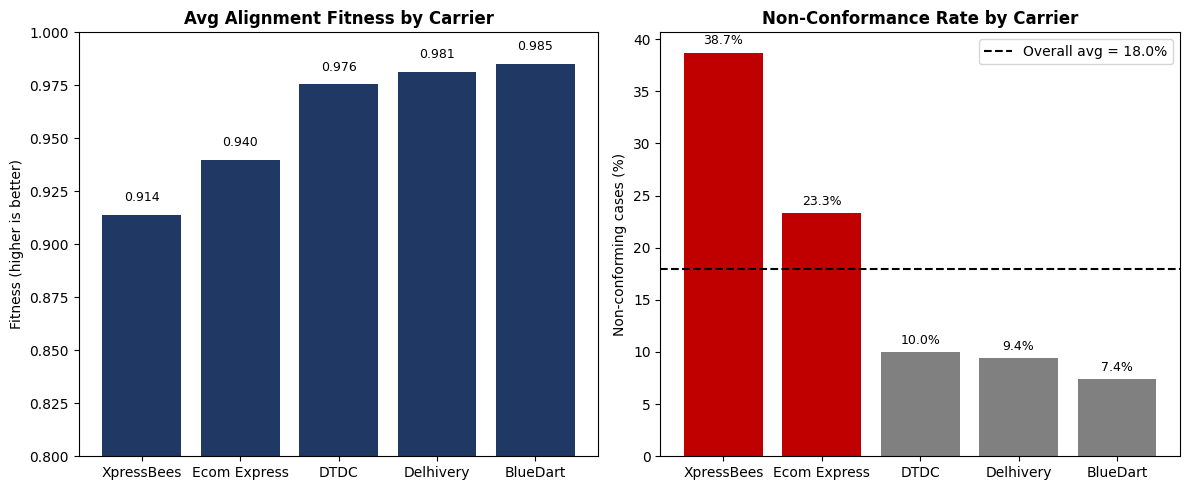

In [29]:
# ── Bonus: KPI Dashboard (Fitness & Non‑Conformance by Carrier) ────────────
# Goal: 2‑panel bar chart: avg fitness (sorted) and non‑conf rate (red/grey threshold).

import matplotlib.pyplot as plt

carriers = carrier_kpi['carrier']
avg_fitness = carrier_kpi['avg_fitness']
nonconf_rate = carrier_kpi['non_conforming_rate']

# Compute overall average non‑conformance rate (weighted by case count)
total_cases = carrier_kpi['case_count'].sum()
total_nonconf = carrier_kpi['non_conforming'].sum()
overall_avg_nonconf = (total_nonconf / total_cases * 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left panel: average fitness
bars1 = ax1.bar(carriers, avg_fitness, color='#1F3864')
ax1.set_title('Avg Alignment Fitness by Carrier', fontname='Arial', fontsize=12, fontweight='bold')
ax1.set_ylabel('Fitness (higher is better)')
ax1.set_ylim(0.8, 1.0)
for bar, val in zip(bars1, avg_fitness):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)

# Right panel: non-conformance rate
colors = ['#C00000' if rate > overall_avg_nonconf else '#808080' for rate in nonconf_rate]
bars2 = ax2.bar(carriers, nonconf_rate, color=colors)
ax2.axhline(y=overall_avg_nonconf, color='black', linestyle='--', label=f'Overall avg = {overall_avg_nonconf:.1f}%')
ax2.set_title('Non-Conformance Rate by Carrier', fontname='Arial', fontsize=12, fontweight='bold')
ax2.set_ylabel('Non‑conforming cases (%)')
ax2.legend()
for bar, val in zip(bars2, nonconf_rate):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('kpi_dashboard_day188.png', dpi=150)
plt.show()

## SECTION 4: Scoring Rubric

| Task | Points | Criteria |
|---|---|---|
| T1 — EventLog + SOP model | 15 | 5 pts variant count/frequencies correct · 5 pts correct happy-path filter · 5 pts correct net place/transition/arc counts |
| T2 — Token-based replay | 20 | 10 pts correct fitness numbers · 10 pts correct explanation of why TBR under-penalizes unmodeled activities |
| T3 — Alignments | 25 | 10 pts correct fitness numbers · 10 pts correct single-case alignment (case, trace, fitness, steps) · 5 pts correct plain-language `'>>'` explanation |
| T4 — Precision/Gen/Simplicity + KPI | 20 | 5 pts each metric (precision, generalization, simplicity) · 5 pts correct carrier KPI table |
| T5 — NRA report | 10 | Number correct (from your own printed output) · Reason is causal mechanism only, no outcome restatement · Action is specific, no hedging — each bullet graded independently |
| **Total** | **90** | |
| Bonus — KPI Dashboard | 10★ | Correct data mapped to bars · correct red/grey threshold logic · `savefig()` before `show()` · dark blue palette + Arial · both panels titled |

**NRA reminders (recurring pattern from Days 181-187):** Reason must stop at the causal mechanism — no
"which reduces X" or "causing Y to happen" tails. Action must name a specific artifact/timeline, never "could"
or "might" or "consider".


## Interview Framing

**"Walk me through how you'd audit whether a company's operations follow their documented process."**

> "I'd pull the event log — every timestamped step per case — and discover a reference model from the
> documented happy path using Inductive Miner. Then I'd run conformance checking two ways: token-based replay
> for a fast first pass, and alignments for the number I'd actually report, since alignments compute the true
> minimal-cost explanation rather than just counting missing tokens on known transitions. On a 150-case shipment
> log, alignments showed only 82% of cases fully matched the documented SOP — TBR misleadingly said 100% because
> it doesn't penalize activities the model has never seen at all. I'd break the 18% non-conforming cases down by
> carrier, which is what turns a metric into a decision: one carrier alone accounted for over a third of all
> deviations, which is where I'd point the operational fix."

This answer works because it (1) names the two competing methods and states *why* one is preferred, (2) gives a
concrete, defensible number, and (3) ends on the business action, not the metric.
